In [1]:
colorMap = <| 1 -> RGBColor[106/255, 170/255, 100/255], 0 -> RGBColor[201/255, 180/255, 80/255], -1 -> RGBColor[134/255, 136/255, 138/255] |>;
tag[word_, target_] := 
  With[{sc = Characters[word], tc = Characters[target]}, 
   With[{neq = Select[Range[5], sc[[#]] != tc[[#]] &]},
    Table[
     Which[sc[[i]] == tc[[i]], 1, 
      MemberQ[tc[[neq]], sc[[i]]] && 
       Length[Position[sc[[neq]][[;; Position[neq, i][[1, 1]]]], 
          sc[[i]]]] <= Length[Position[tc[[neq]], sc[[i]]]], 0, 
      True, -1], {i, 5}]]];
WordlePlot[ss_List, target_] := Column[WordlePlot[#, target] & /@ ss];
WordlePlot[s_String, target_] := 
  With[{sc = Characters[s], tc = Characters[target], colors = colorMap /@ tag[s, target]},
    Row[Table[
      Graphics[{colors[[i]], Rectangle[], White, 
        Text[Style[sc[[i]], FontSize -> 48, 
          FontFamily -> "Clear Sans", Bold, White], {.5, .5}]}], {i, 
       5}]]
   ];

-Graphics--Graphics--Graphics--Graphics--Graphics-
-Graphics--Graphics--Graphics--Graphics--Graphics-
-Graphics--Graphics--Graphics--Graphics--Graphics-
-Graphics--Graphics--Graphics--Graphics--Graphics-
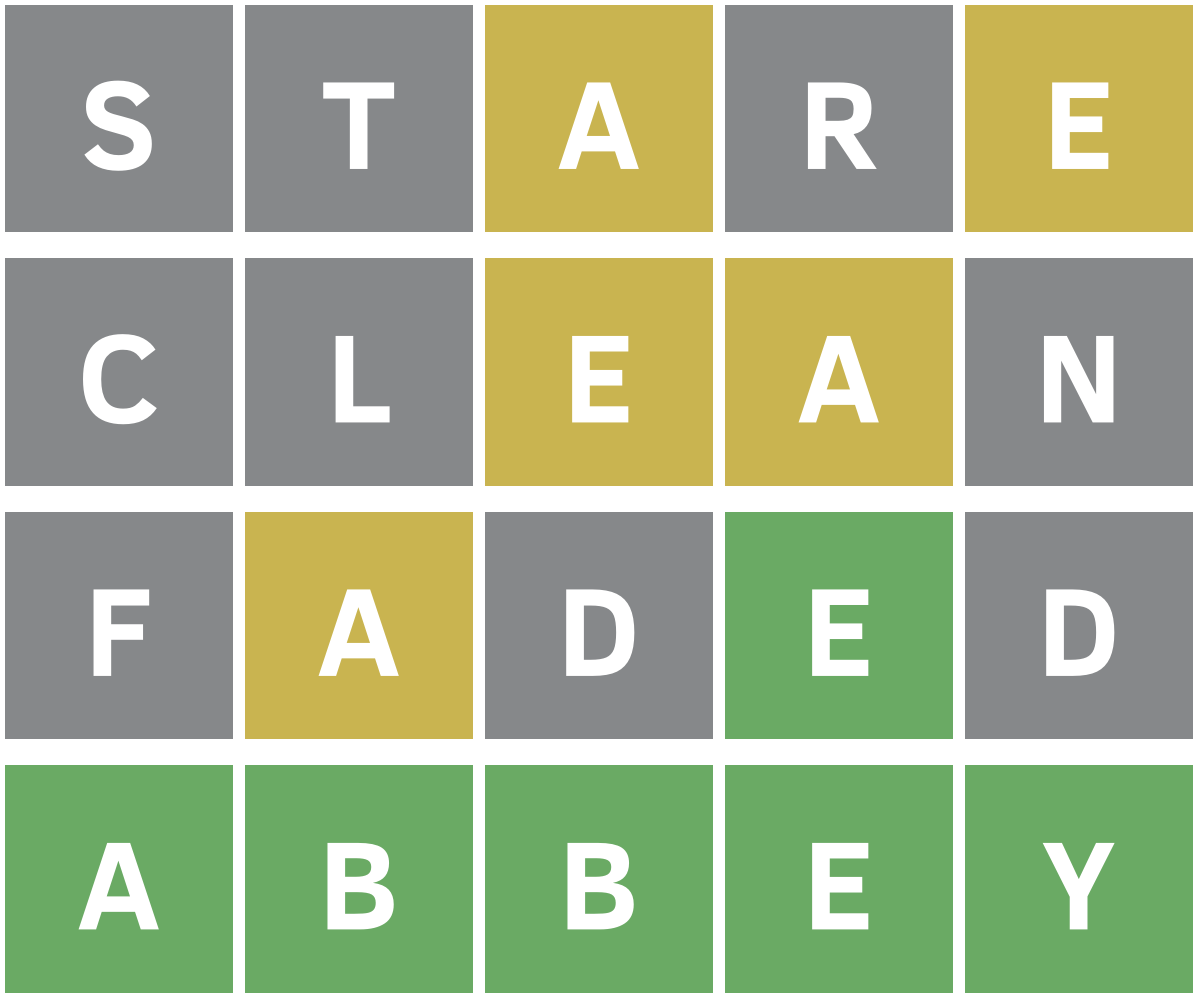

In [5]:
WordlePlot[{"STARE", "CLEAN", "FADED", "ABBEY"}, "ABBEY"]

-Graphics-
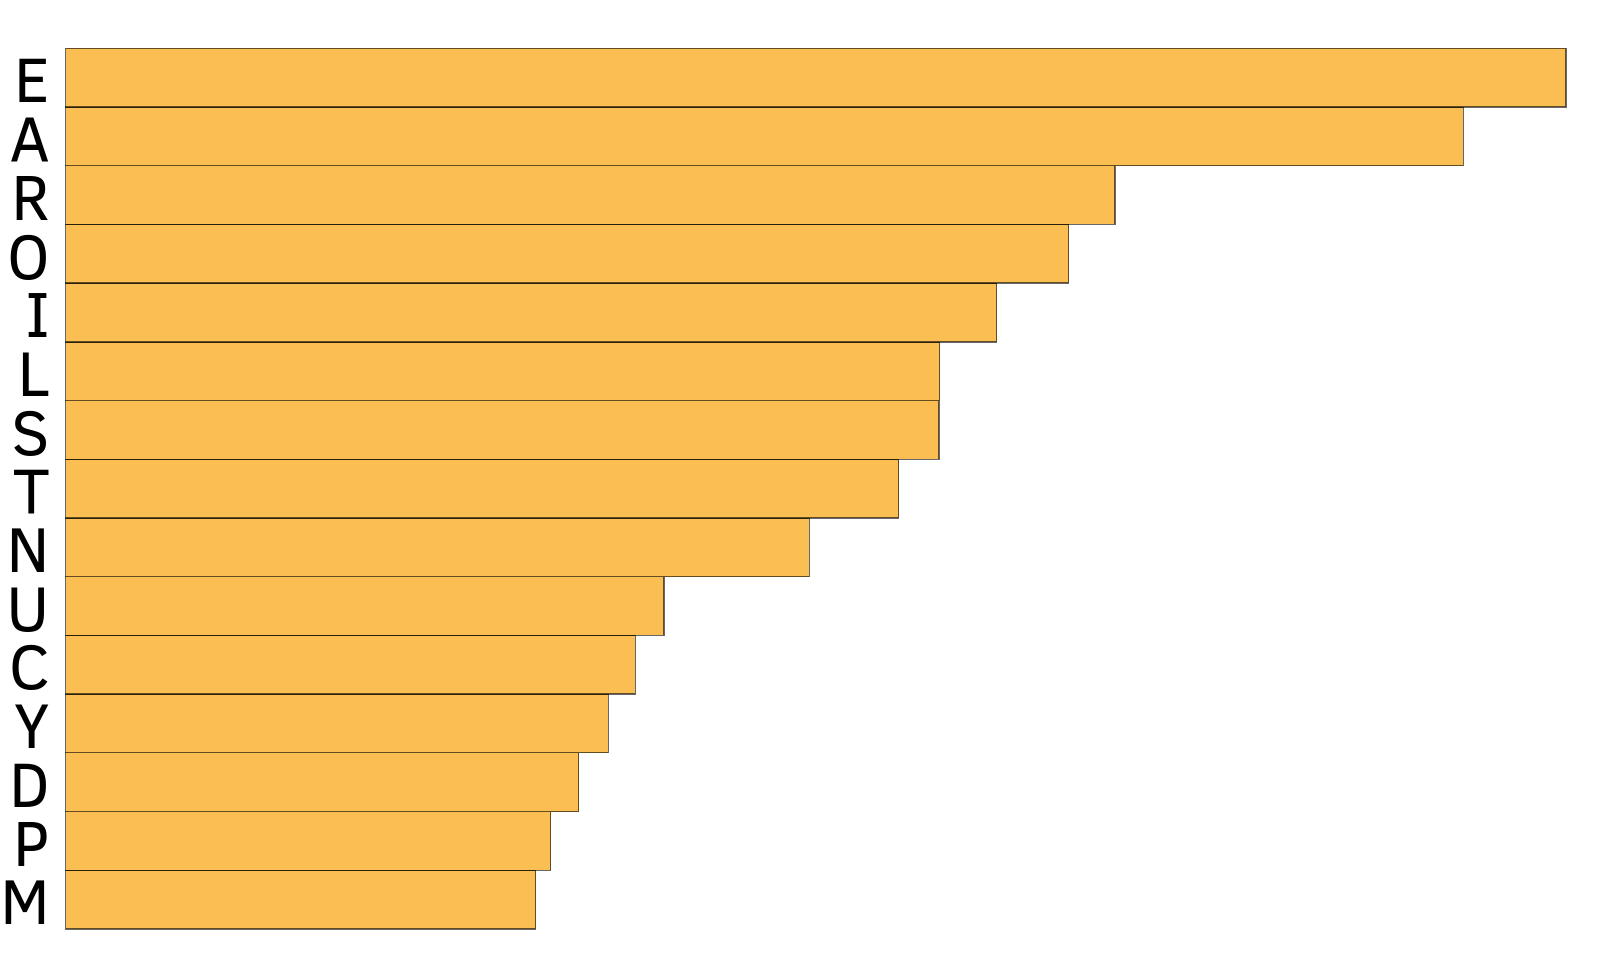

In [8]:
words = ToUpperCase /@ Select[WordList["KnownWords"], 
    StringLength[#] == 5 && AllTrue[Characters[#], x |-> MemberQ[CharacterRange["a", "z"], x]] &];
chardata = Association[Rule @@@ ReverseSortBy[Tally@Flatten@Characters@words, Last]];

BarChart[Labeled[#2, 
    Style[#1, FontSize -> 24, FontFamily -> "Clear Sans"], Before] & @@@
   Reverse@Take[Normal@chardata, 15], BarSpacing -> 0, 
 BarOrigin -> Left, Axes -> False, ImageSize -> 600]

1    ORATE    (8206)

2    RAISE    (8161)

3    ARISE    (8161)

4    IRATE    (8104)

5    LASER    (8080)

6    ARLES    (8080)

7    RATEL    (8023)

8    LATER    (8023)

9    ALTER    (8023)

10   ALERT    (8023)

11   TERAS    (8022)

12   TEARS    (8022)

13   STARE    (8022)

14   RATES    (8022)

15   ASTER    (8022)
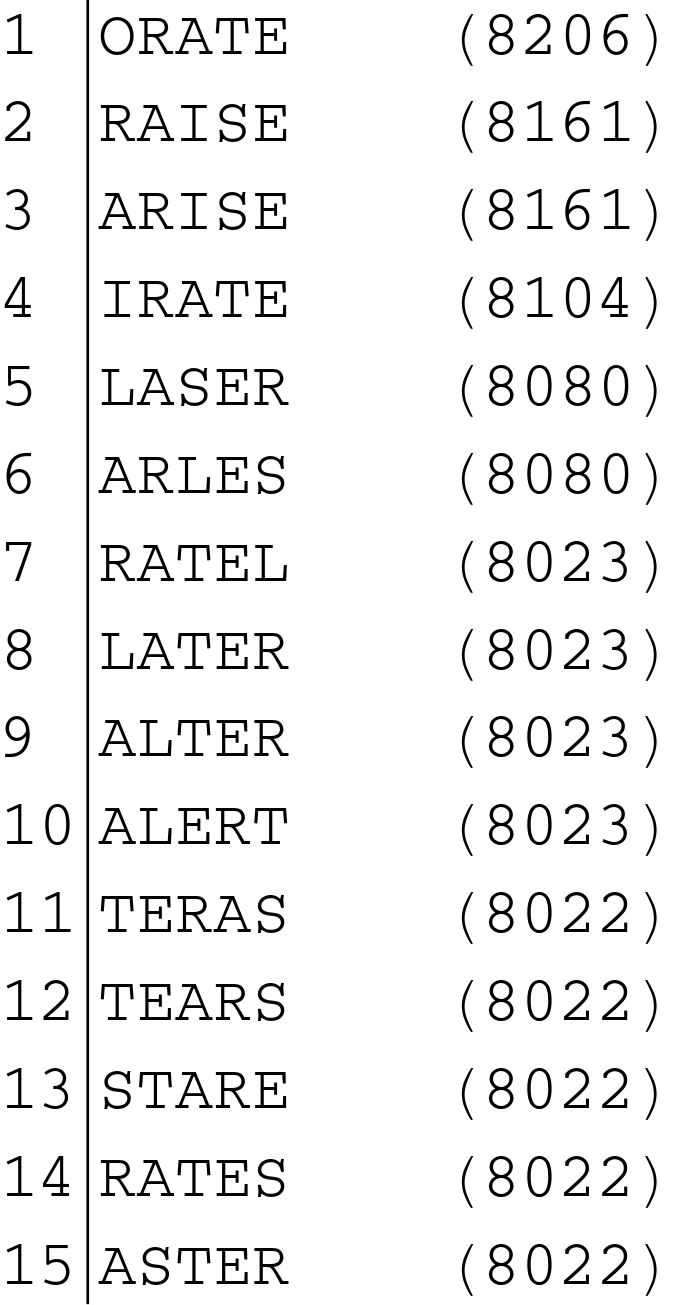

In [11]:
score[word_] := Total[chardata /@ Union[Characters[word]]]
scores = {#, score[#]} & /@ words;

TableForm[
 Style[First[#] <> "    (" <> ToString[Last[#]] <> ")", 
    FontSize -> 24, FontFamily -> "Courier New"] & /@ 
  Take[ReverseSortBy[scores, Last], 15], 
 TableHeadings -> {Style[#, FontSize -> 24, 
      FontFamily -> "Courier New"] & /@ Range[15], {}}]

In [13]:
guessData[guesses_, target_] := AssociationMap[w |-> tag[w, target], guesses];
gd = guessData[{"STARE", "CLEAN"}, "ABBEY"]

<|STARE -> {-1, -1, 0, -1, 0}, CLEAN -> {-1, -1, 0, 0, -1}|>

In [15]:
candidates[guessData_, words_] := Select[words, candidate |-> AllTrue[Keys @ guessData, tag[#, candidate] == guessData[#] &]]
candidates[gd, words]

{ABBEY, ADIEU, AIDED, BAKED, DAZED, FADED, FAMED, FAZED, FOVEA, GAMEY, GEMMA, HOVEA, 
 
>   JADED, JAWED, MAMEY, MAZED, PAVED, WAXED}

In [7]:
maxRemaining[start_, words_] := 
 Last@SortBy[Table[{tup, Length[candidates[<|start -> tup|>, words]]}, {tup, Tuples[{-1, 0, 1}, 5]}], Last]

In [17]:
Length[words]
maxRemaining["STARE", words]
maxRemaining["ORATE", words]

4198
{{-1, -1, -1, -1, -1}, 419}
{{-1, -1, 0, -1, -1}, 338}

In [20]:
Length[candidates[<| "ORATE" -> {-1, -1, -1, -1, -1} |>, words]]

338

In [10]:
maxRemaining[start_, words_] := 
 Last@SortBy[Table[{tup, Length[candidates[<|start -> tup|>, words]]}, {tup, Tuples[{-1, 0}, 5]}], Last]

#1   -Graphics--Graphics--Graphics--Graphics--Graphics-          286





#2   -Graphics--Graphics--Graphics--Graphics--Graphics-          328





#3   -Graphics--Graphics--Graphics--Graphics--Graphics-          330





#4   -Graphics--Graphics--Graphics--Graphics--Graphics-          332





#5   -Graphics--Graphics--Graphics--Graphics--Graphics-          338
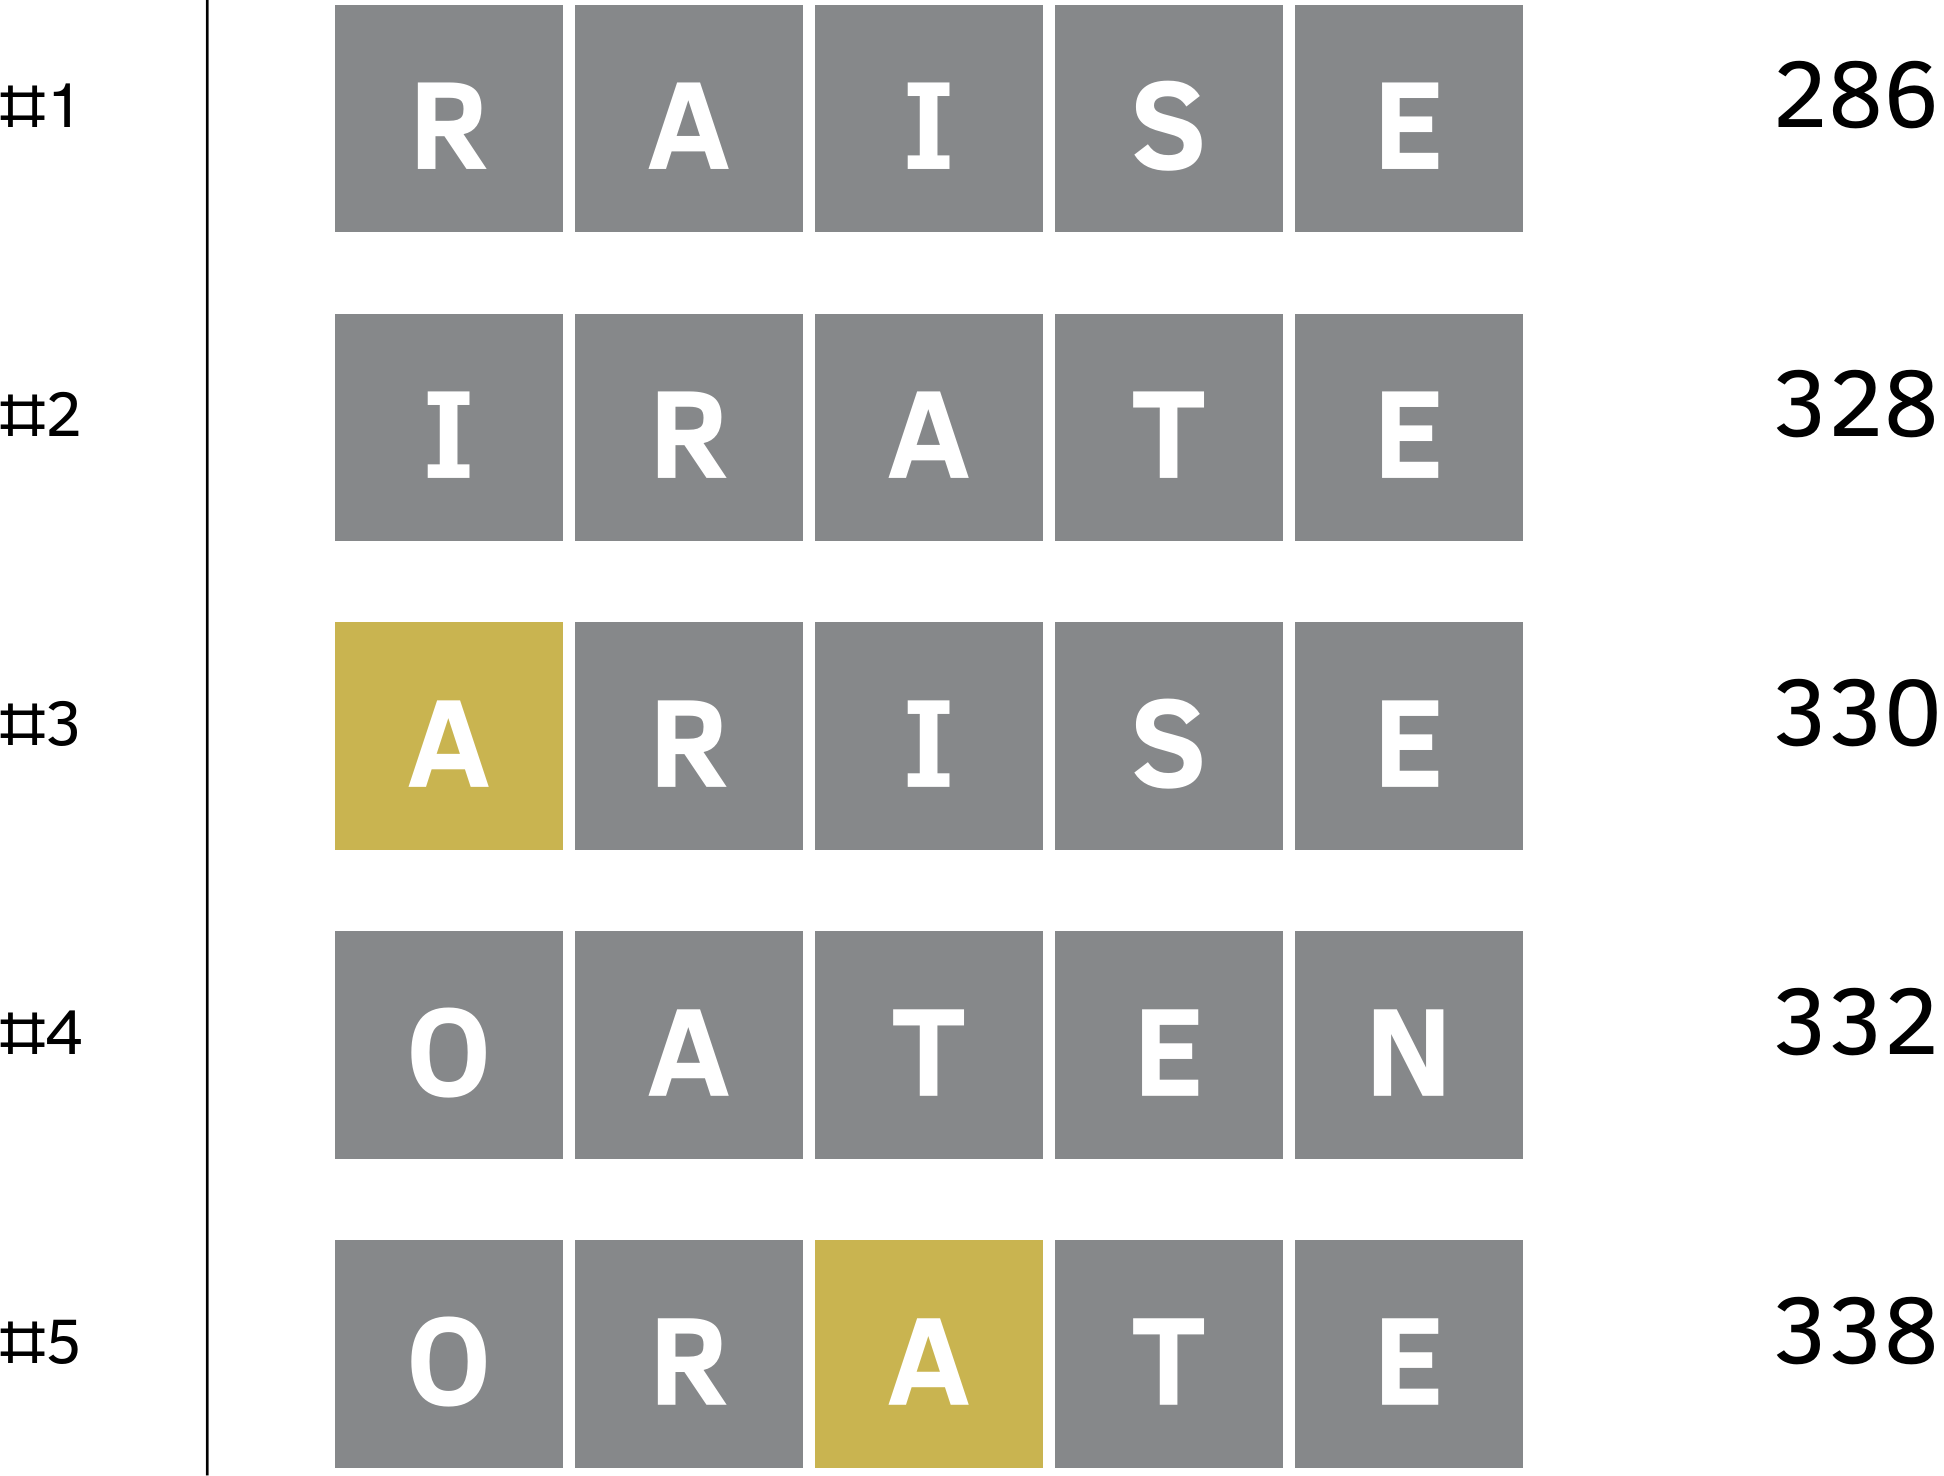

In [24]:
contestants = First /@ Take[ReverseSortBy[scores, Last], 30];
ranking[cs_, words_] := With[{data = SortBy[
   Table[With[{mr = maxRemaining[w, words]}, {WordlePlot[w, 
       First@candidates[<|w -> mr[[1]]|>, words]], 
      Style[mr[[2]], FontSize -> 36, 
       FontFamily -> "Clear Sans"]}], {w, cs}], Last]},
TableForm[data[[;;5]], TableSpacing -> {5, 10}, 
 TableHeadings -> {(Style["#" <> ToString@#, 24, 
       FontFamily -> "Clear Sans"] & /@ Range[5]), None}]
];

ranking[contestants, words]

{ALOES, ARISE, RAISE, ADIEU, ATOLE}
#1   -Graphics--Graphics--Graphics--Graphics--Graphics-          286





#2   -Graphics--Graphics--Graphics--Graphics--Graphics-          328





#3   -Graphics--Graphics--Graphics--Graphics--Graphics-          330





#4   -Graphics--Graphics--Graphics--Graphics--Graphics-          332





#5   -Graphics--Graphics--Graphics--Graphics--Graphics-          338
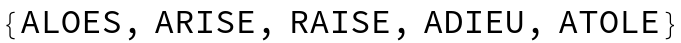
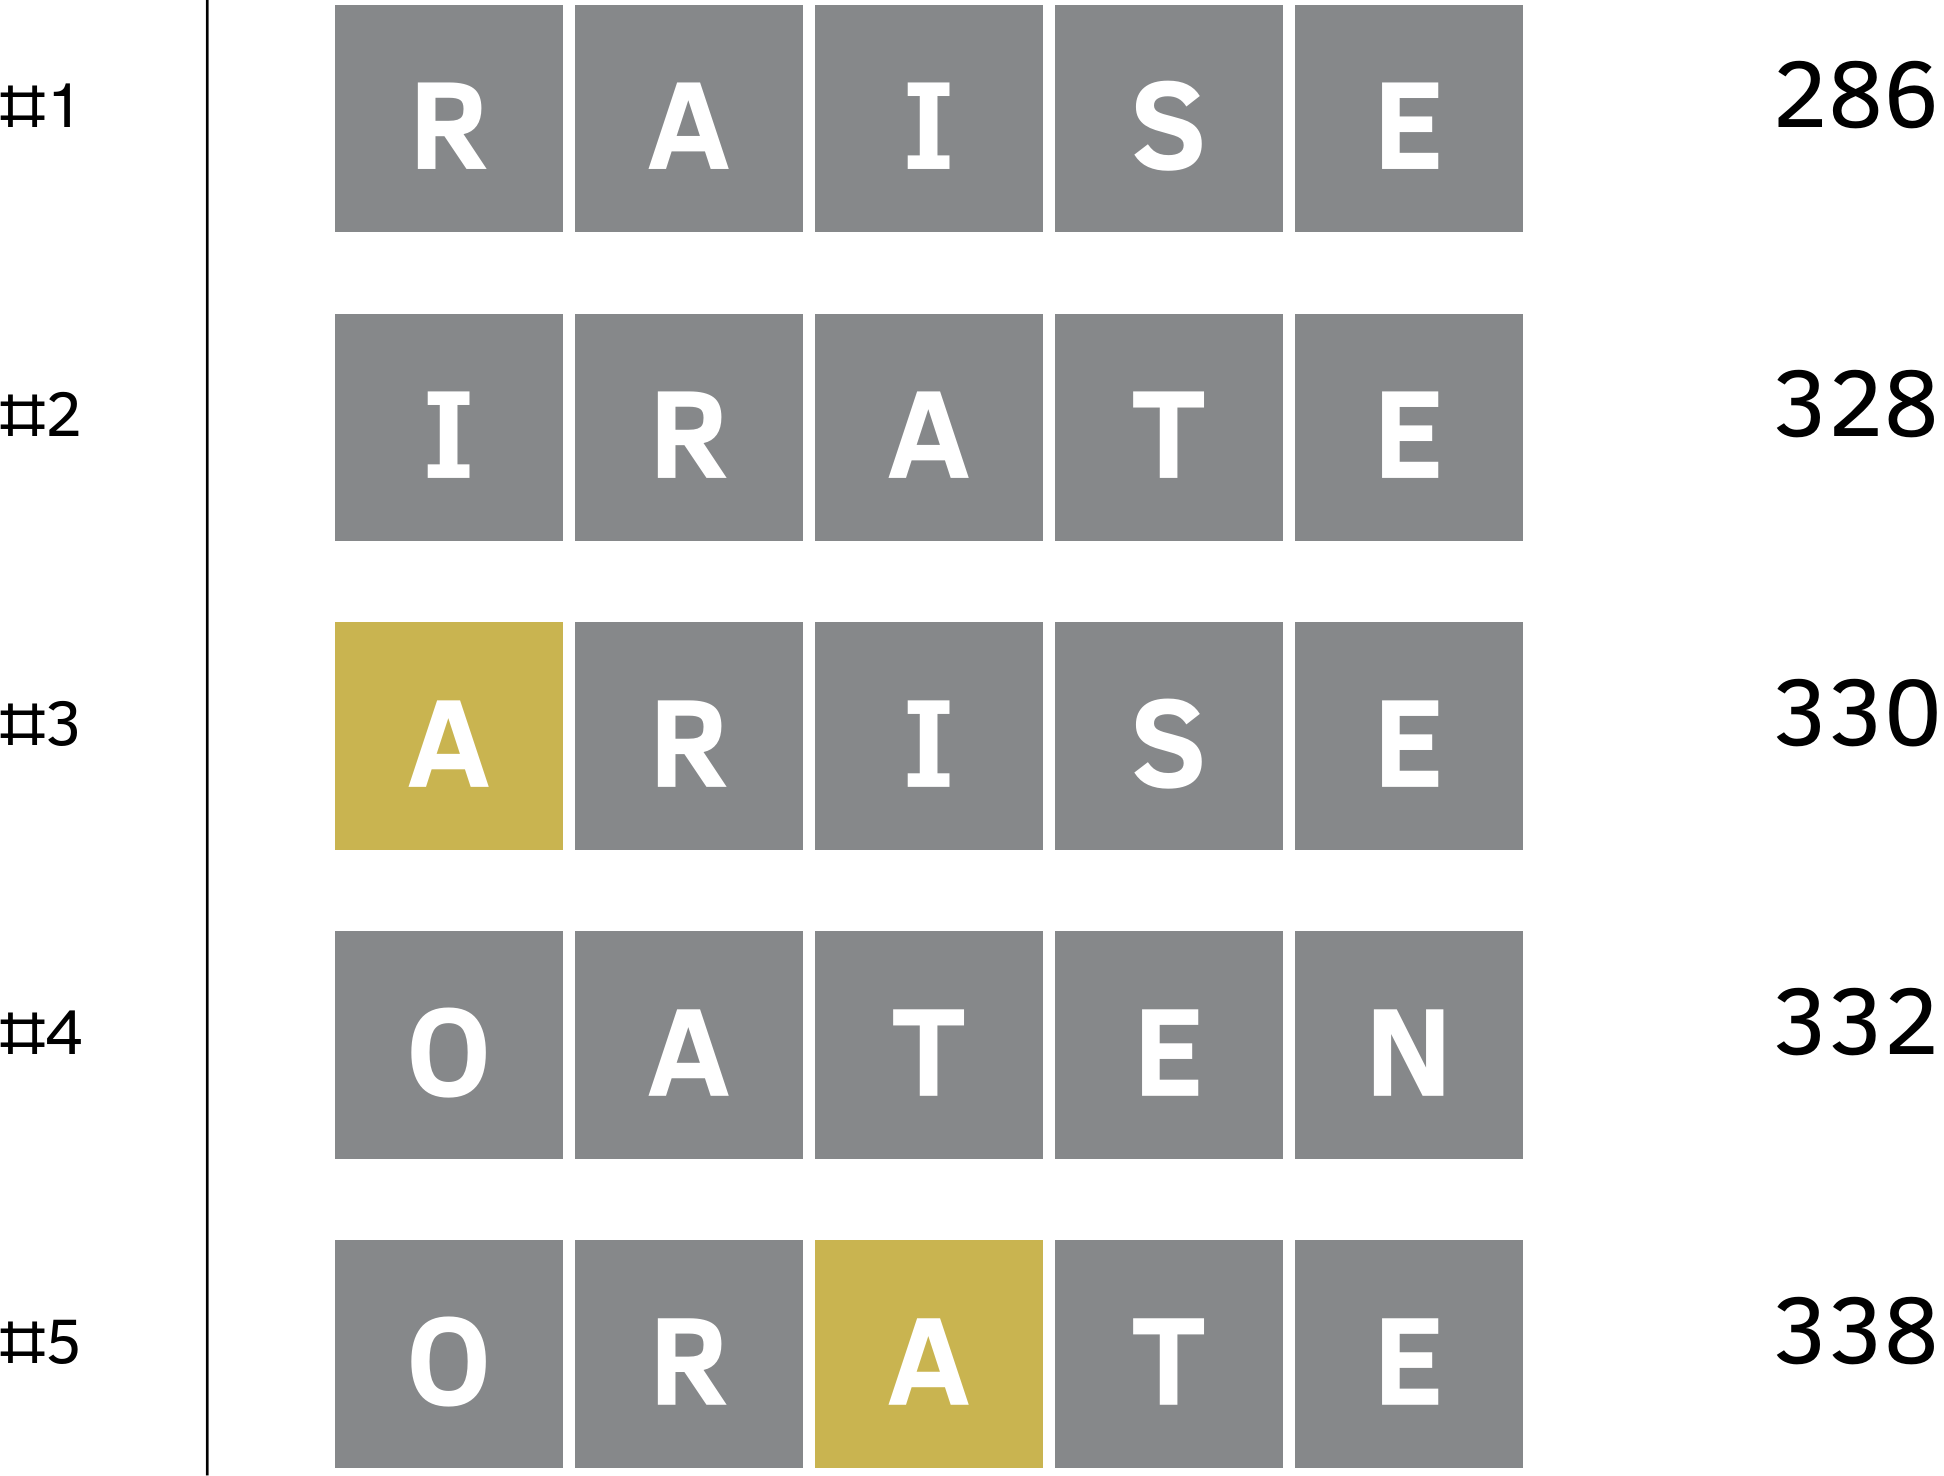

In [28]:
nonOverlapping[w1_, w2_] := 
  Length[Intersection[Characters[w1], Characters[w2]]] == 0;
grayScore[w_, words_] := Length[Select[words, nonOverlapping[#, w] &]];
newContestants = SortBy[words, grayScore[#, words] &][[;; 30]];

newContestants[[;;5]]

ranking[newContestants, words]

#1   -Graphics--Graphics--Graphics--Graphics--Graphics-          15





#2   -Graphics--Graphics--Graphics--Graphics--Graphics-          17





#3   -Graphics--Graphics--Graphics--Graphics--Graphics-          21





#4   -Graphics--Graphics--Graphics--Graphics--Graphics-          24





#5   -Graphics--Graphics--Graphics--Graphics--Graphics-          27
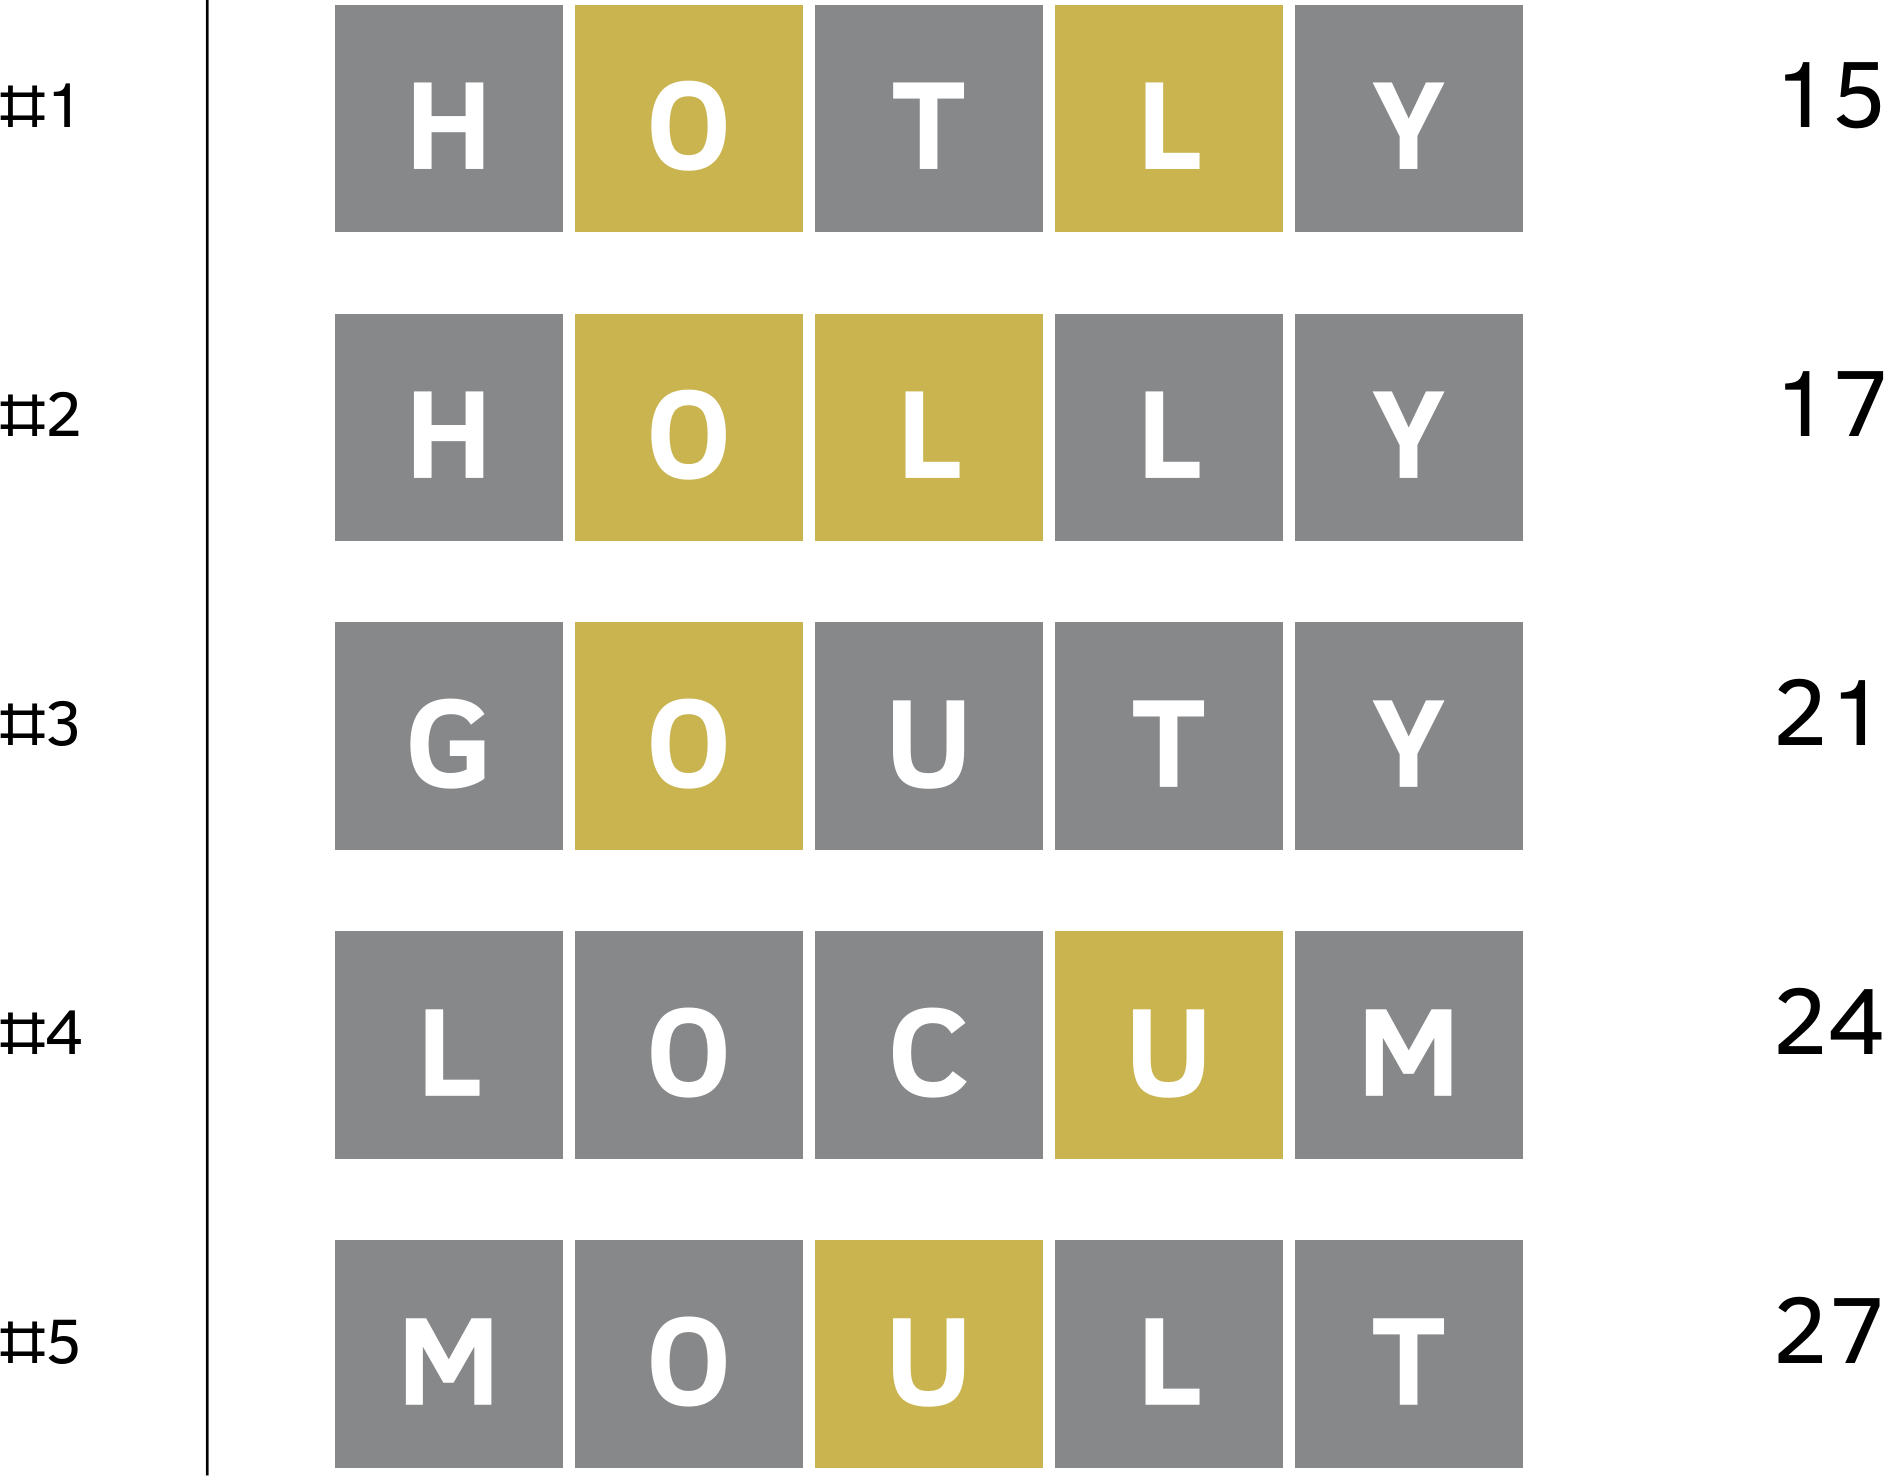

In [32]:
raiseWords = candidates[<| "RAISE" -> {-1, -1, -1, -1, -1} |>, words];

raiseContestants = SortBy[raiseWords, grayScore[#, raiseWords] &][[;; 30]];

ranking[raiseContestants, raiseWords]

#1





#2   -Graphics--Graphics--Graphics--Graphics--Graphics-          4





#3   -Graphics--Graphics--Graphics--Graphics--Graphics-          4





#4   -Graphics--Graphics--Graphics--Graphics--Graphics-          5





#5   -Graphics--Graphics--Graphics--Graphics--Graphics-          5
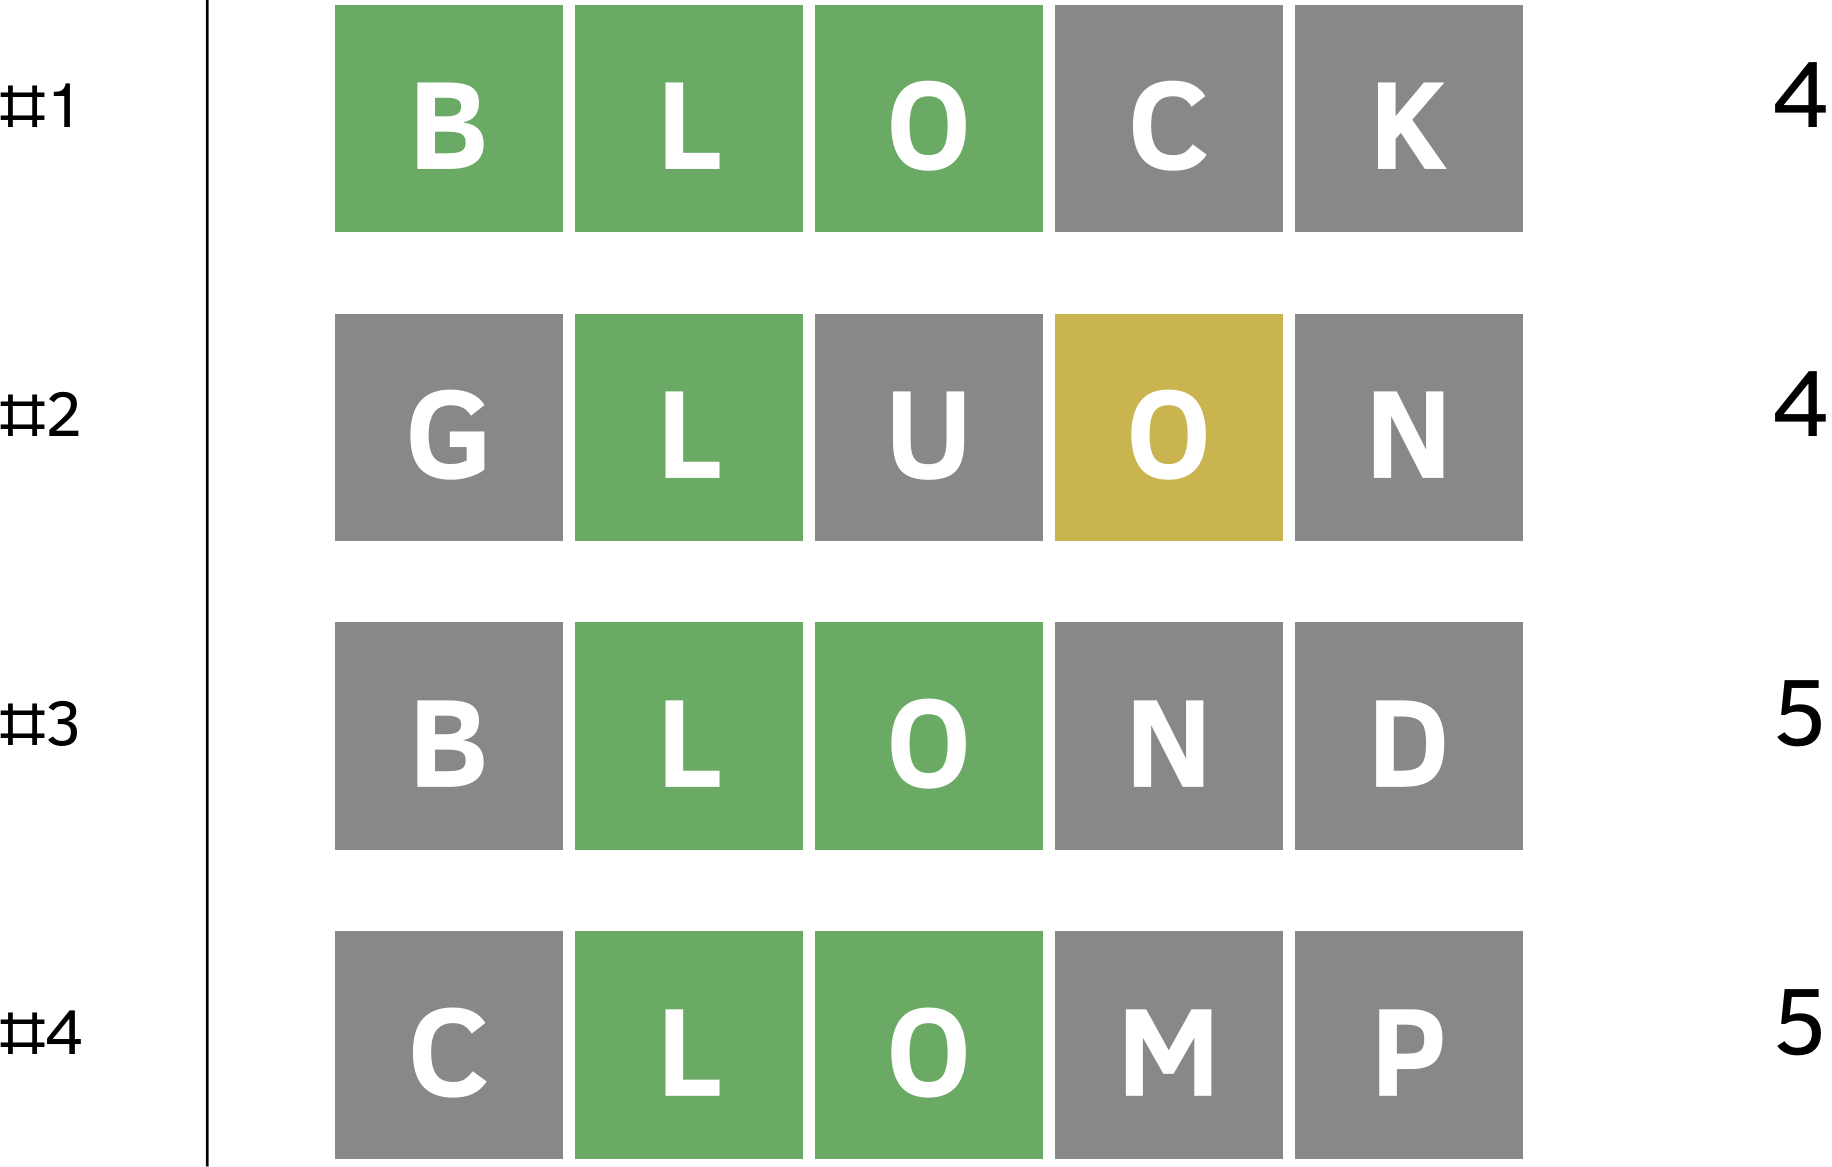

In [35]:
raiseHotlyWords = 
  candidates[<|"HOTLY" -> {-1, 0, -1, 0, -1}|>, raiseWords];

ranking[words_] := With[{data = SortBy[
         Table[
       With[{mr = 
          Last@SortBy[
            Table[{w2, 
              Length[candidates[<|w -> tag[w, w2]|>, words]]}, {w2, 
              words}], Last]}, {WordlePlot[w, 
                mr[[1]]], 
               Style[mr[[2]], FontSize -> 36, 
                 FontFamily -> "Clear Sans"]}], {w, words}], Last]},
   TableForm[data[[;; 4]], TableSpacing -> {5, 10}, 
     TableHeadings -> {(Style["#" <> ToString@#, 24, 
                 FontFamily -> "Clear Sans"] & /@ Range[5]), None}]
   ];

ranking[raiseHotlyWords]

#1





#2   -Graphics--Graphics--Graphics--Graphics--Graphics-          1





#3   -Graphics--Graphics--Graphics--Graphics--Graphics-          1





#4   -Graphics--Graphics--Graphics--Graphics--Graphics-          2





#5   -Graphics--Graphics--Graphics--Graphics--Graphics-          2
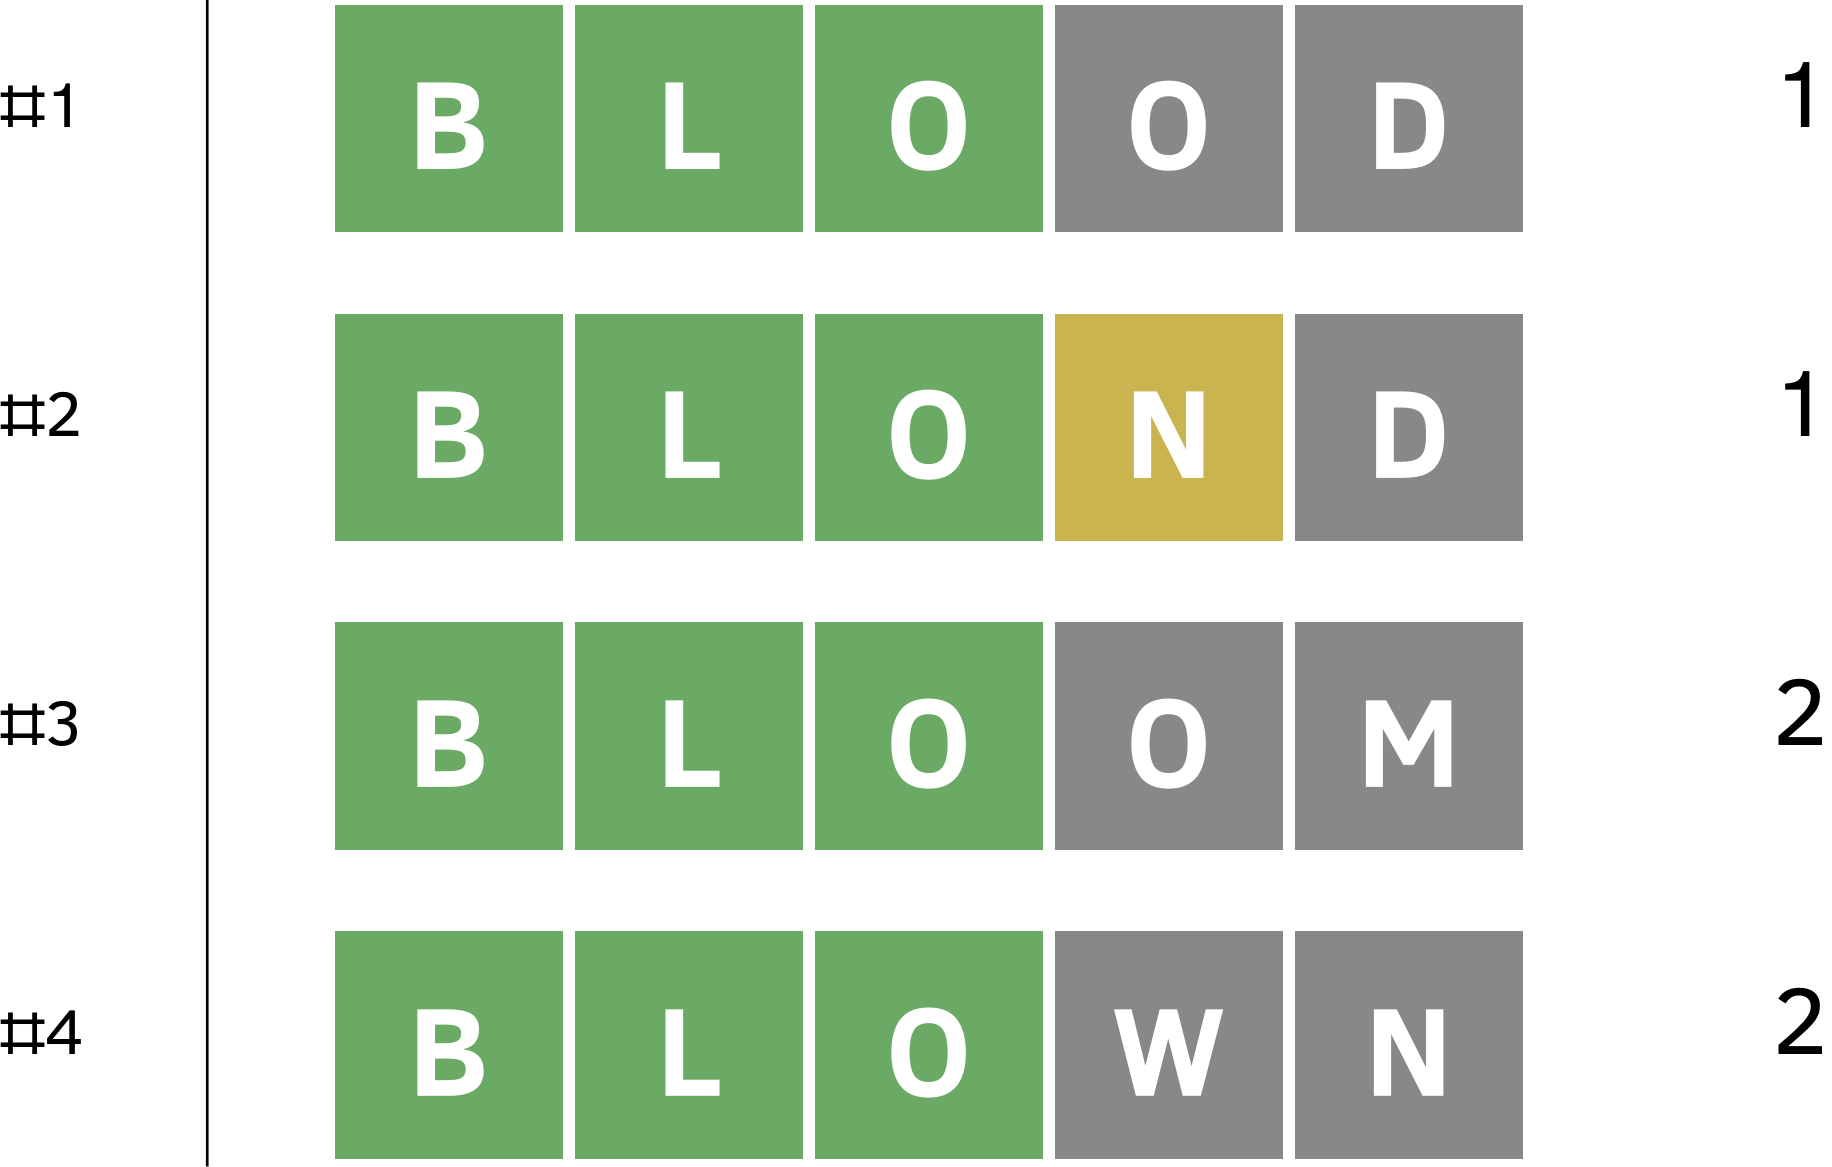

In [37]:
raiseHotlyBlockWords = 
  candidates[<|"BLOCK" -> {1, 1, 1, -1, -1}|>, raiseHotlyWords];
ranking[raiseHotlyBlockWords]

-Graphics--Graphics--Graphics--Graphics--Graphics-
-Graphics--Graphics--Graphics--Graphics--Graphics-
-Graphics--Graphics--Graphics--Graphics--Graphics-
-Graphics--Graphics--Graphics--Graphics--Graphics-
-Graphics--Graphics--Graphics--Graphics--Graphics-
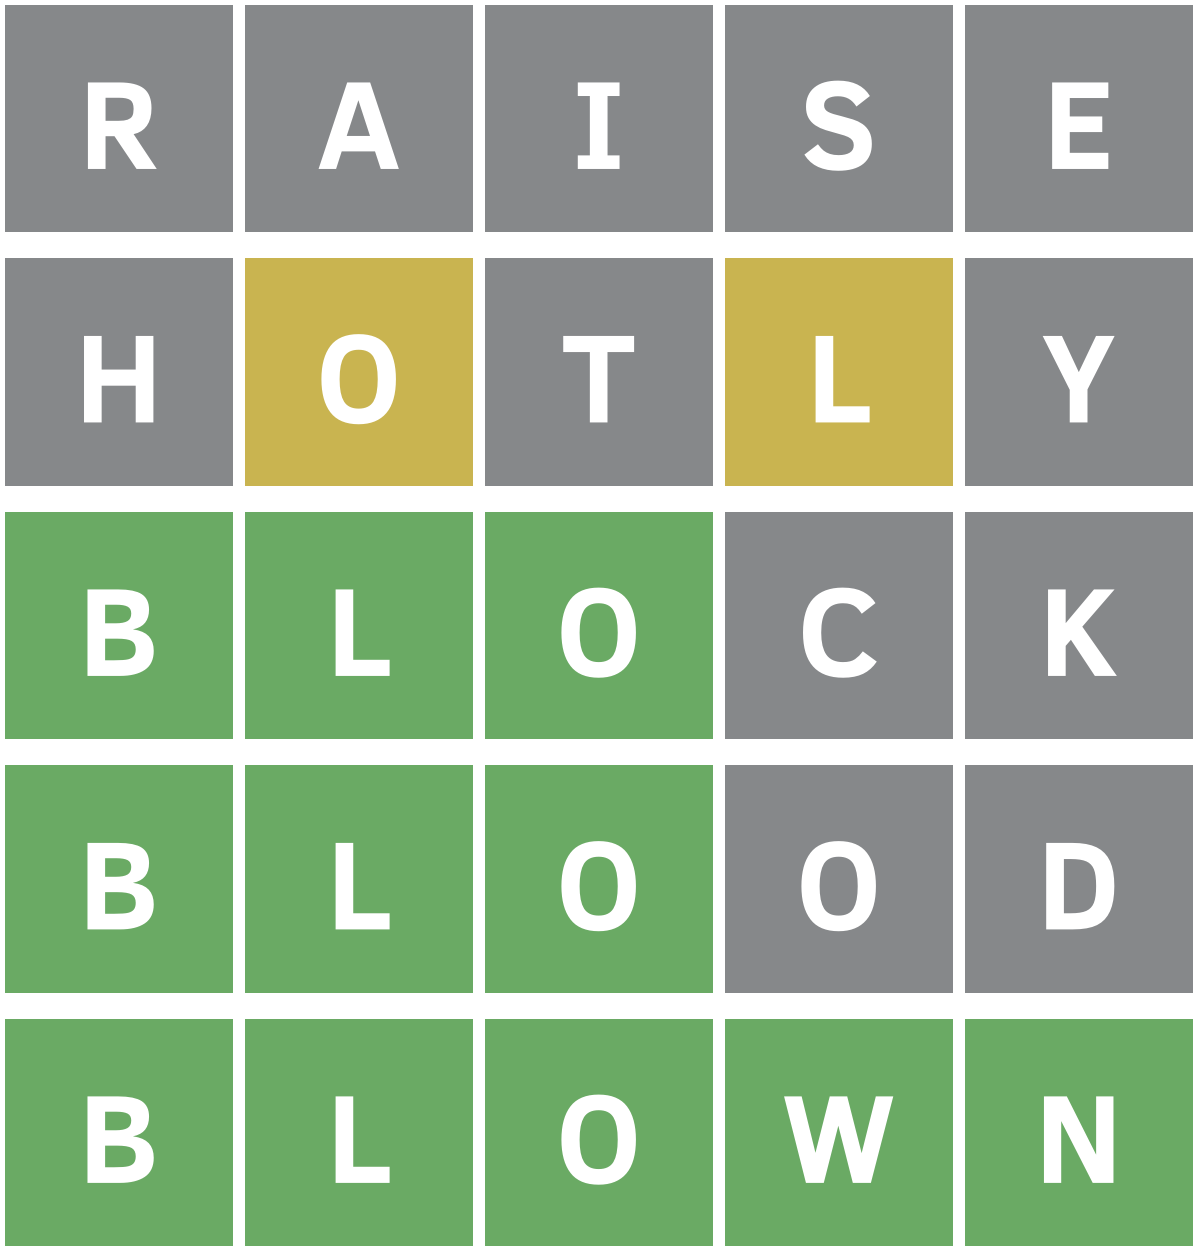

In [38]:
WordlePlot[{"RAISE", "HOTLY", "BLOCK", "BLOOD", "BLOWN"}, "BLOWN"]